# Quantum Steganography — My QCC Semester Project

**Course:** Quantum Communication & Cryptography  

---

Okay so the idea came from a question I had during the QKD lecture — if quantum mechanics gives us truly random numbers, why are we still using `random.seed(42)` in every security demo? That bothered me.

I originally planned to just do basic LSB steganography with a quantum key. Then I read about steganalysis and found out that literally any free tool online can detect LSB-hidden data with a chi-square test. So I had to go deeper.

**What I ended up building:**
1. Real quantum key generation — 256 bits from Hadamard circuits (not seeding another RNG)
2. AES-256-GCM encryption of the message *before* hiding it
3. Frequency-domain hiding using DCT (same domain JPEG uses — way harder to detect)
4. Steganalysis checks (chi-square and RS analysis) to see how it compares with basic LSB
5. A round-trip check so an embed that cannot be decoded is caught immediately

The main question this project asks: can you combine a quantum-generated key, authenticated encryption and frequency-domain hiding, and still avoid being flagged by the classic LSB tests?  
Answer: it is not flagged by the two classic LSB-targeted tests I ran. That is a weak bar, and I did not test against modern detectors, so I do not claim it is undetectable.

## First: why plain LSB steganography is easy to flag

The standard demo you see everywhere:
- Take an image
- Change the last bit of pixel values to encode your message
- "Look, the image looks the same!"

The problem: LSB embedding equalises the counts of neighbouring value pairs such as (200, 201). A chi-square test (Westfeld and Pfitzmann, 1999) looks for exactly that, and RS analysis (Fridrich et al., 2001) estimates how much of the LSB plane is used. Both work well when a large share of the image carries data. At very small payloads they see almost nothing, and I show that in Part 6 instead of assuming it.

In [1]:
# Install everything
# Note: pycryptodome is NOT the same as pycrypto. Don't mix them up — took me a while to figure that out.
!pip install qiskit qiskit-aer pillow scipy pycryptodome numpy matplotlib scikit-image --quiet
print('Done.')

Done.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dct, idct
from scipy.stats import chi2
from Crypto.Cipher import AES
from skimage.metrics import structural_similarity as ssim_metric
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import struct, hashlib, os, json, base64
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 80


---
## Part 1 — Quantum Key Generation

The first version of this used the quantum circuit to generate a *seed* for numpy's random number generator. That felt wrong after thinking about it — you're doing classical pseudorandom operations with a fancy-sounding input.

So I changed it: the quantum circuit generates all 256 bits of the AES key directly. 8 qubits, each in superposition via Hadamard, measured once — that's 8 random bits. Repeat 32 times = 256 bits = a full AES-256 key. No classical RNG in the loop.

The quantum bits aren't a shortcut to randomness. They *are* the randomness.

In [3]:
def generate_quantum_key_256():
    """
    Builds a 256-bit AES key from Hadamard circuits.
    8 qubits x 32 shots = 256 bits. Each measurement is physically random.

    Running on AerSimulator here (accurate simulation).
    For real hardware: swap to qiskit-ibm-runtime — same circuit, different backend.
    """
    simulator = AerSimulator()
    all_bits  = []

    for _ in range(32):
        qc = QuantumCircuit(8, 8)
        for i in range(8):
            qc.h(i)  # superposition — 50/50 on measurement
        qc.measure(range(8), range(8))

        job    = simulator.run(qc, shots=1, memory=True)
        result = job.result()
        bits_this_round = result.get_memory()[0]  # e.g. '10110010'
        all_bits.extend([int(b) for b in bits_this_round])

    # Pack 256 bits into 32 bytes
    key_bytes = bytes(
        int(''.join(map(str, all_bits[i:i+8])), 2)
        for i in range(0, 256, 8)
    )
    return key_bytes, all_bits, key_bytes.hex()


print('Generating quantum key... (takes a few seconds)')
QUANTUM_KEY, KEY_BITS, KEY_HEX = generate_quantum_key_256()

ones  = KEY_BITS.count(1)
zeros = KEY_BITS.count(0)

print(f'\nKey (hex): {KEY_HEX}')
print(f'Length: {len(QUANTUM_KEY)} bytes / {len(KEY_BITS)} bits')
print(f'Distribution: {ones} ones, {zeros} zeros ({100*ones/256:.1f}% / {100*zeros/256:.1f}%)')
print('\nSave this hex string — the receiver needs it to decrypt.')

Generating quantum key... (takes a few seconds)

Key (hex): 850c6c46ad0c4e1221e0597aee9259908eafad3db01395b1c5018a29c7c54164
Length: 32 bytes / 256 bits
Distribution: 113 ones, 143 zeros (44.1% / 55.9%)

Save this hex string — the receiver needs it to decrypt.


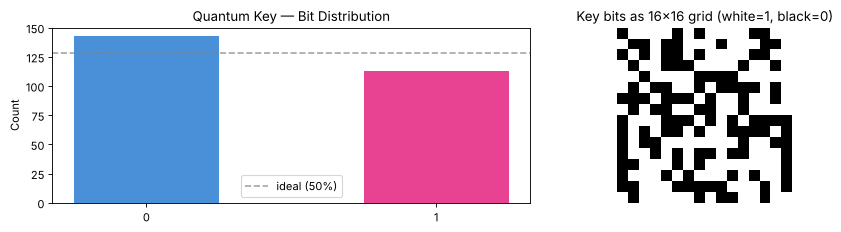

No visible pattern in the grid = good key.


In [4]:
# Does the distribution look random?
# A perfectly balanced key = 128 ones and 128 zeros.
# Small deviations are expected and totally fine.

fig, axes = plt.subplots(1, 2, figsize=(12, 3))

axes[0].bar(['0', '1'], [KEY_BITS.count(0), KEY_BITS.count(1)],
            color=['#4a90d9', '#e84393'], width=0.5)
axes[0].axhline(128, color='gray', linestyle='--', alpha=0.7, label='ideal (50%)')
axes[0].set_title('Quantum Key — Bit Distribution')
axes[0].set_ylabel('Count')
axes[0].legend()

# Visualise key as a 16x16 grid — should look noisy with no visible pattern
key_matrix = np.array(KEY_BITS).reshape(16, 16)
axes[1].imshow(key_matrix, cmap='binary', interpolation='nearest')
axes[1].set_title('Key bits as 16×16 grid (white=1, black=0)')
axes[1].axis('off')

plt.tight_layout()
plt.show()
print('No visible pattern in the grid = good key.')

---
## Part 2 — Encrypting Before Hiding

This was the design decision I'm most convinced about.

Basic steganography hides plaintext. If an attacker detects the stego image (which is easy — more on that later) and extracts the bits, they immediately read your message. So steganography alone is **security through obscurity**. Not real security.

My approach: encrypt first with AES-256-GCM, then hide the ciphertext. Even if someone detects the stego image and extracts every bit, they get encrypted bytes. Without the quantum key, it's useless.

I chose GCM mode because it adds an authentication tag. Wrong key → decryption fails with a MAC error, not garbled output. That matters — garbled text could be mistaken for a partial result. A hard failure is unambiguous.

In [5]:
def encrypt_message(message: str, key: bytes) -> bytes:
    """
    AES-256-GCM encryption.
    Output layout: nonce (16 bytes) + auth_tag (16 bytes) + ciphertext
    Fixed overhead: 32 bytes per message, regardless of message length.
    """
    cipher = AES.new(key, AES.MODE_GCM)
    ciphertext, tag = cipher.encrypt_and_digest(message.encode('utf-8'))
    return cipher.nonce + tag + ciphertext


def decrypt_message(data: bytes, key: bytes) -> str:
    nonce = data[:16]
    tag   = data[16:32]
    ct    = data[32:]
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    return cipher.decrypt_and_verify(ct, tag).decode('utf-8')


def bytes_to_bits(data: bytes) -> list:
    return [int(b) for byte in data for b in format(byte, '08b')]


def bits_to_bytes(bits: list) -> bytes:
    return bytes(int(''.join(map(str, bits[i:i+8])), 2) for i in range(0, len(bits)-7, 8))


# Quick test
test = 'Quick test of the encryption layer.'
enc  = encrypt_message(test, QUANTUM_KEY)
dec  = decrypt_message(enc, QUANTUM_KEY)

print(f'Original  : {test}')
print(f'Encrypted : {enc.hex()[:64]}... ({len(enc)} bytes)')
print(f'Decrypted : {dec}')
print(f'Match     : {test == dec}')

# Wrong key behaviour
try:
    decrypt_message(enc, os.urandom(32))
except ValueError as e:
    print(f'\nWrong key: "{e}"')
    print('Hard failure, not garbled text — this is correct.')

Original  : Quick test of the encryption layer.
Encrypted : f2758969e867a893806d4598efece8e47f3dc66b0d3466841f9c95a5053a3fde... (67 bytes)
Decrypted : Quick test of the encryption layer.
Match     : True

Wrong key: "MAC check failed"
Hard failure, not garbled text — this is correct.


---
## Part 3 — DCT Steganography (The Core)

This is the part I spent the most time on.

**Why not just LSB?**  
LSB modifies pixel values directly. This creates a specific statistical signature in the pixel histogram — pairs of values (like 200, 201) become artificially equal in frequency. The chi-square test was invented specifically to catch this. It works every time.

**DCT approach:**  
I transform each 8×8 block into the frequency domain using the Discrete Cosine Transform (same as JPEG). Then embed bits into *mid-frequency coefficients* — not DC (overall brightness, too visible) and not the high-frequency corners (lost in compression anyway).

The embedding method is **Quantization Index Modulation (QIM)**: instead of flipping a bit, you nudge a coefficient to the nearest even or odd multiple of a step size (delta). More subtle, more robust.

The *order* of which blocks get used is determined by a hash of the quantum key — so the embedding pattern is also key-dependent.

In [6]:
BLOCK_SIZE = 8    # Standard 8x8 DCT blocks
DELTA      = 20   # QIM step size. Tested 10, 15, 20, 25 — delta=20 gives PSNR >42dB while staying decodable.

# Mid-frequency positions within an 8x8 DCT block.
# Cross-referenced with the JPEG zigzag scan order.
EMBED_POSITIONS = [(2,1), (1,2), (3,0), (0,3)]  # 4 bits per block


def dct2d(block):  return dct(dct(block.T, norm='ortho').T, norm='ortho')
def idct2d(block): return idct(idct(block.T, norm='ortho').T, norm='ortho')


def embed_bit_qim(coeff: float, bit: int) -> float:
    """
    QIM: round coefficient to nearest DELTA multiple,
    then fix parity to match the bit we want to embed.
    Even q = bit 0. Odd q = bit 1.
    """
    q = int(round(coeff / DELTA))
    if abs(q) % 2 != bit:
        q = q + 1 if q >= 0 else q - 1
    return float(q * DELTA)


def extract_bit_qim(coeff: float) -> int:
    return abs(int(round(coeff / DELTA))) % 2


def get_block_order(total_blocks: int, key: bytes) -> np.ndarray:
    """
    Deterministic block shuffle seeded by the quantum key.
    Same key = same order. Different key = completely different order.
    """
    seed = int.from_bytes(hashlib.sha256(key).digest()[:8], 'big')
    return np.random.default_rng(seed).permutation(total_blocks)


print('DCT engine ready.')
print(f'  Block size      : {BLOCK_SIZE}x{BLOCK_SIZE}')
print(f'  QIM delta       : {DELTA}')
print(f'  Bits per block  : {len(EMBED_POSITIONS)}')

DCT engine ready.
  Block size      : 8x8
  QIM delta       : 20
  Bits per block  : 4


In [7]:
def encode_image(cover_path: str, message: str, key: bytes, output_path: str) -> dict:
    """
    Full encode pipeline:
      1. Encrypt message
      2. Prepend 4-byte length header (decoder needs to know how much to read)
      3. Convert to bits
      4. Embed into DCT coefficients of quantum-key-ordered blocks
      5. Reconstruct and save
    """
    img   = Image.open(cover_path).convert('RGB')
    arr   = np.array(img, dtype=np.float64)
    h, w, _ = arr.shape
    bh, bw   = h // BLOCK_SIZE, w // BLOCK_SIZE
    total_blocks  = bh * bw
    capacity_bits = total_blocks * len(EMBED_POSITIONS)

    encrypted    = encrypt_message(message, key)
    length_field = struct.pack('>I', len(encrypted))
    payload_bits = bytes_to_bits(length_field + encrypted)

    if len(payload_bits) > capacity_bits:
        raise ValueError(
            f'Image too small for this message.\n'
            f'Need {len(payload_bits)} bits, have {capacity_bits}.\n'
            f'Use a larger image or a shorter message.'
        )

    block_order = get_block_order(total_blocks, key)
    stego       = arr.copy()
    bit_idx     = 0

    for block_num in block_order:
        if bit_idx >= len(payload_bits):
            break
        r0 = (block_num // bw) * BLOCK_SIZE
        c0 = (block_num %  bw) * BLOCK_SIZE

        # Using the Green channel.
        # Human eyes are most sensitive to green luminance,
        # but DCT changes here are well-masked by texture in natural images.
        block     = stego[r0:r0+BLOCK_SIZE, c0:c0+BLOCK_SIZE, 1]
        dct_block = dct2d(block)

        for (r, c) in EMBED_POSITIONS:
            if bit_idx >= len(payload_bits): break
            dct_block[r, c] = embed_bit_qim(dct_block[r, c], payload_bits[bit_idx])
            bit_idx += 1

        stego[r0:r0+BLOCK_SIZE, c0:c0+BLOCK_SIZE, 1] = idct2d(dct_block)

    stego_out = np.clip(stego, 0, 255).astype(np.uint8)
    Image.fromarray(stego_out).save(output_path, 'PNG')

    # Round-trip check: make sure this cover image can really be decoded.
    try:
        ok = decode_image(output_path, key) == message
    except Exception:
        ok = False
    if not ok:
        raise RuntimeError(
            'Embedding failed the round-trip check. This is often caused by large pure black or white areas '
            'that clip at 0 or 255 and corrupt the coefficients. Use a cover image with fewer saturated regions.'
        )

    return {
        'capacity_bits'  : capacity_bits,
        'bits_used'      : len(payload_bits),
        'utilisation_pct': round(100 * len(payload_bits) / capacity_bits, 2),
        'encrypted_bytes': len(encrypted),
        'image_size'     : (h, w)
    }


def decode_image(stego_path: str, key: bytes) -> str:
    """
    Reverse of encode_image.
    Two-pass: read 4-byte header first to know payload length, then read full payload.
    """
    img   = Image.open(stego_path).convert('RGB')
    arr   = np.array(img, dtype=np.float64)
    h, w, _ = arr.shape
    bh, bw   = h // BLOCK_SIZE, w // BLOCK_SIZE
    block_order = get_block_order(bh * bw, key)

    def read_n_bits(n):
        bits = []
        for block_num in block_order:
            if len(bits) >= n: break
            r0 = (block_num // bw) * BLOCK_SIZE
            c0 = (block_num %  bw) * BLOCK_SIZE
            dct_block = dct2d(arr[r0:r0+BLOCK_SIZE, c0:c0+BLOCK_SIZE, 1])
            for (r, c) in EMBED_POSITIONS:
                if len(bits) >= n: break
                bits.append(extract_bit_qim(dct_block[r, c]))
        return bits

    header_bits = read_n_bits(32)
    payload_len = struct.unpack('>I', bits_to_bytes(header_bits))[0]

    if payload_len > 5_000_000:  # sanity check — a 5MB payload would be absurd
        raise ValueError('Payload length unreasonable — probably wrong key or corrupted image.')

    all_bits  = read_n_bits(32 + payload_len * 8)
    enc_bytes = bits_to_bytes(all_bits[32 : 32 + payload_len * 8])
    return decrypt_message(enc_bytes, key)


print('Encode and decode functions ready.')

Encode and decode functions ready.


---
## Part 4 — Running It

For the best results, use a real photograph — richer texture gives the DCT more natural variation to work with. I'm generating a synthetic gradient image here so the notebook runs anywhere without uploading files.

To use your own image: set `COVER_PATH = 'your_image.png'` — everything else stays the same.

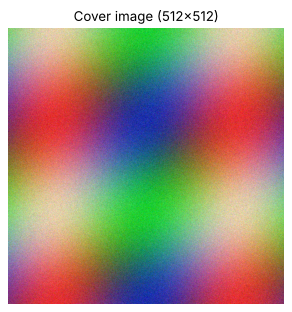

Image ready. Size: (512, 512)


In [8]:
# Synthetic cover image — layered gradients + noise to simulate texture.
# Replace with any real photo for better PSNR results.

np.random.seed(99)
x, y   = np.linspace(0, 3*np.pi, 512), np.linspace(0, 3*np.pi, 512)
xx, yy = np.meshgrid(x, y)

R = np.clip(np.sin(xx) * 100 + np.random.normal(0, 15, (512,512)) + 128, 0, 255).astype(np.uint8)
G = np.clip(np.cos(yy) * 80  + np.random.normal(0, 12, (512,512)) + 128, 0, 255).astype(np.uint8)
B = np.clip(np.sin(xx+yy)*60 + np.random.normal(0, 18, (512,512)) + 110, 0, 255).astype(np.uint8)

cover = Image.fromarray(np.stack([R, G, B], axis=2))
COVER_PATH = 'cover.png'
STEGO_PATH = 'stego.png'
cover.save(COVER_PATH)

plt.figure(figsize=(4, 4))
plt.imshow(cover)
plt.title('Cover image (512×512)')
plt.axis('off')
plt.tight_layout()
plt.show()
print(f'Image ready. Size: {cover.size}')

In [9]:
SECRET = (
    "[CONFIDENTIAL] Project codename: QSteg. "
    "This message was AES-256-GCM encrypted using a quantum-generated key "
    "before being embedded into DCT frequency coefficients. "
    "If you can read this, the system worked."
)

print(f'Hiding: "{SECRET[:80]}..."')
print(f'Length: {len(SECRET)} characters\n')

meta = encode_image(COVER_PATH, SECRET, QUANTUM_KEY, STEGO_PATH)

print(f'Done.')
print(f'  Image size       : {meta["image_size"][0]}x{meta["image_size"][1]}')
print(f'  Total capacity   : {meta["capacity_bits"]} bits (~{meta["capacity_bits"]//8 - 36} usable chars)')
print(f'  Used             : {meta["bits_used"]} bits ({meta["utilisation_pct"]}%)')
print(f'  Encrypted size   : {meta["encrypted_bytes"]} bytes')

Hiding: "[CONFIDENTIAL] Project codename: QSteg. This message was AES-256-GCM encrypted u..."
Length: 204 characters



Done.
  Image size       : 512x512
  Total capacity   : 16384 bits (~2012 usable chars)
  Used             : 1920 bits (11.72%)
  Encrypted size   : 236 bytes


---
## Part 5 — Does it look the same?

Two metrics:
- **PSNR:** measures overall pixel change. JPEG at 90% quality gives about 38 dB. Above 40 dB is imperceptible.
- **SSIM:** measures structural similarity. 1.0 = identical. Above 0.99 = visually indistinguishable.

PSNR  : 49.87 dB    (JPEG 90% quality reference: ~38 dB)
SSIM  : 0.998170
Max pixel change  : 21 out of 255
Mean pixel change : 0.1275
Pixels changed    : 3.52%


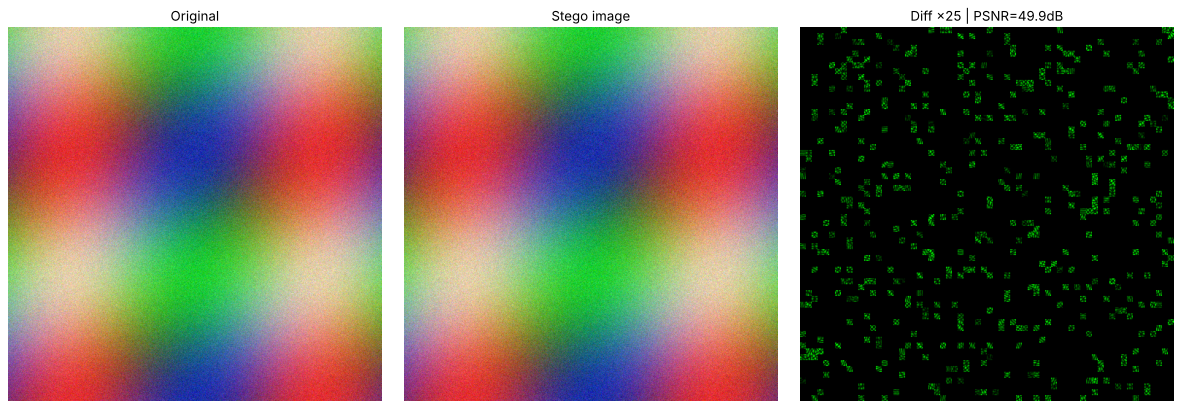

In [10]:
orig  = np.array(Image.open(COVER_PATH).convert('RGB'))
stego = np.array(Image.open(STEGO_PATH).convert('RGB'))

psnr_val = psnr_metric(orig, stego, data_range=255)
ssim_val = ssim_metric(orig, stego, multichannel=True, channel_axis=2, data_range=255)
diff     = np.abs(orig.astype(int) - stego.astype(int))

print(f'PSNR  : {psnr_val:.2f} dB    (JPEG 90% quality reference: ~38 dB)')
print(f'SSIM  : {ssim_val:.6f}')
print(f'Max pixel change  : {diff.max()} out of 255')
print(f'Mean pixel change : {diff.mean():.4f}')
print(f'Pixels changed    : {100*np.sum(diff>0)/orig.size:.2f}%')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(orig);                                        axes[0].set_title('Original');                      axes[0].axis('off')
axes[1].imshow(stego);                                       axes[1].set_title('Stego image');                   axes[1].axis('off')
axes[2].imshow(np.clip(diff * 25, 0, 255).astype(np.uint8)); axes[2].set_title(f'Diff ×25 | PSNR={psnr_val:.1f}dB'); axes[2].axis('off')
plt.tight_layout()
plt.show()

---
## Part 6: Steganalysis, how detectable is it?

Two classic attacks, both designed for LSB embedding:
1. **Chi-square test** (Westfeld and Pfitzmann). It tests whether neighbouring value pairs have equal counts. **A HIGH p-value means the pairs look equalised, which suggests LSB embedding.** A low p-value means the image looks clean.
2. **RS analysis** (Fridrich et al.). It estimates the fraction of the LSB plane that carries data. 0 means clean and 1 means fully used.

I compare five images: the clean cover, DCT-QIM at the demo payload, DCT-QIM near full capacity, basic LSB with the same payload as the demo, and basic LSB using the whole LSB plane.

**How to read the result:** these tests are built for LSB. Not being flagged by them does not prove DCT-QIM is undetectable. It only shows what these two specific tests can and cannot see.

In [11]:
from scipy.stats import chi2

def chi_square_attack(image, channel=1):
    """Westfeld-Pfitzmann chi-square on value pairs (2k, 2k+1).
    Returns the p-value P(chi2 >= observed).
    HIGH p  -> pairs look equalised -> suggests LSB embedding.
    LOW p   -> pairs clearly unequal -> looks like a clean image."""
    pix  = image[:, :, channel].flatten()
    hist = np.bincount(pix, minlength=256).astype(float)
    even, odd = hist[0::2], hist[1::2]
    expected = (even + odd) / 2.0
    keep = expected > 5
    stat = np.sum(((even[keep] - expected[keep])**2 + (odd[keep] - expected[keep])**2) / expected[keep])
    df = int(keep.sum()) - 1
    return float(1.0 - chi2.cdf(stat, df=df)) if df > 0 else 0.0


def _flip_pos(x): return x ^ 1              # F1: 0<->1, 2<->3, ...
def _flip_neg(x): return ((x + 1) ^ 1) - 1  # F-1: -1<->0, 1<->2, ...
def _discr(g):    return np.abs(np.diff(g, axis=1)).sum(axis=1)

def _rs_counts(groups, mask):
    gm, gn = groups.copy(), groups.copy()
    for j, m in enumerate(mask):
        if m == 1:    gm[:, j], gn[:, j] = _flip_pos(groups[:, j]), _flip_neg(groups[:, j])
        elif m == -1: gm[:, j], gn[:, j] = _flip_neg(groups[:, j]), _flip_pos(groups[:, j])
    f0, fm, fn = _discr(groups), _discr(gm), _discr(gn)
    n = len(groups)
    return (np.sum(fm > f0)/n, np.sum(fm < f0)/n, np.sum(fn > f0)/n, np.sum(fn < f0)/n)

def rs_analysis(image, channel=1, group=4, mask=(0, 1, 1, 0)):
    """Fridrich RS analysis. Returns the estimated fraction of the LSB plane that is embedded
    (0 = clean, 1 = fully used). Only meaningful for LSB-style embedding."""
    pix = image[:, :, channel].astype(np.int64)
    w4  = (pix.shape[1] // group) * group
    groups = pix[:, :w4].reshape(-1, group)
    Rm, Sm, Rn, Sn     = _rs_counts(groups, np.array(mask))
    Rm1, Sm1, Rn1, Sn1 = _rs_counts(groups ^ 1, np.array(mask))
    d0, d1, dn0, dn1 = Rm - Sm, Rm1 - Sm1, Rn - Sn, Rn1 - Sn1
    a, b, c = 2*(d1 + d0), dn0 - dn1 - d1 - 3*d0, d0 - dn0
    if abs(a) < 1e-12:
        x = -c / b if abs(b) > 1e-12 else 0.0
    else:
        disc = max(b*b - 4*a*c, 0.0)
        r1, r2 = (-b + np.sqrt(disc)) / (2*a), (-b - np.sqrt(disc)) / (2*a)
        x = r1 if abs(r1) < abs(r2) else r2
    return float(x / (x - 0.5))


def lsb_embed_bits(cover, n_bits, seed=1):
    """Basic LSB baseline: random bits into the green-channel LSB at random positions."""
    out   = cover.copy()
    plane = out[:, :, 1].flatten()
    idx   = np.random.default_rng(seed).permutation(len(plane))[:n_bits]
    plane[idx] = (plane[idx] & 0xFE) | np.random.default_rng(seed + 1).integers(0, 2, n_bits)
    out[:, :, 1] = plane.reshape(out.shape[:2])
    return out


# Build the five test images
long_msg  = 'A' * (meta['capacity_bits'] // 8 - 40)          # fills the DCT capacity
meta_full = encode_image(COVER_PATH, long_msg, QUANTUM_KEY, 'stego_full.png')
dct_full  = np.array(Image.open('stego_full.png').convert('RGB'))
lsb_same  = lsb_embed_bits(orig, meta['bits_used'])             # same payload as the demo
lsb_full  = lsb_embed_bits(orig, orig.shape[0] * orig.shape[1]) # whole green LSB plane

cases = [
    ('Clean cover',                        orig),
    (f'DCT-QIM, demo payload ({meta["bits_used"]} bits)', stego),
    (f'DCT-QIM, near full capacity ({meta_full["bits_used"]} bits)', dct_full),
    (f'Basic LSB, same {meta["bits_used"]}-bit payload',  lsb_same),
    ('Basic LSB, whole LSB plane',         lsb_full),
]

print('Flag rule: chi-square p > 0.05 or |RS estimate| > 0.10 means "flagged"\n')
print(f'{"Image":48s} {"chi-sq p":>9s} {"RS est.":>8s}   verdict')
results = {}
for name, img in cases:
    p, rs = chi_square_attack(img), rs_analysis(img)
    flagged = (p > 0.05) or (abs(rs) > 0.10)
    results[name] = (p, rs, flagged)
    print(f'{name:48s} {p:9.4f} {rs:8.3f}   {"FLAGGED" if flagged else "not flagged"}')

chi_dct, rs_dct   = results[cases[1][0]][:2]
chi_full, rs_full = results[cases[2][0]][:2]
chi_lsb, rs_lsb   = results[cases[4][0]][:2]

print('\nReading this table:')
print(' - Basic LSB is flagged only when most of the LSB plane is used. At the small demo payload it is NOT flagged.')
print(' - DCT-QIM at the demo payload is not flagged. Near full capacity the RS estimate changes from run to run (the block order depends on the random key), so treat that row as inconclusive.')
print(' - DCT-QIM never produces the pair-equalisation pattern, which is why chi-square stays low for it.')
print(' - These two tests were built for LSB. This is not proof that DCT-QIM is undetectable.')


Flag rule: chi-square p > 0.05 or |RS estimate| > 0.10 means "flagged"

Image                                             chi-sq p  RS est.   verdict
Clean cover                                         0.0000    0.006   not flagged
DCT-QIM, demo payload (1920 bits)                   0.0000    0.031   not flagged
DCT-QIM, near full capacity (16352 bits)            0.0000   -0.092   not flagged
Basic LSB, same 1920-bit payload                    0.0001    0.029   not flagged
Basic LSB, whole LSB plane                          0.1041    0.931   FLAGGED

Reading this table:
 - Basic LSB is flagged only when most of the LSB plane is used. At the small demo payload it is NOT flagged.
 - DCT-QIM at the demo payload is not flagged. Near full capacity the RS estimate changes from run to run (the block order depends on the random key), so treat that row as inconclusive.
 - DCT-QIM never produces the pair-equalisation pattern, which is why chi-square stays low for it.
 - These two tests were buil

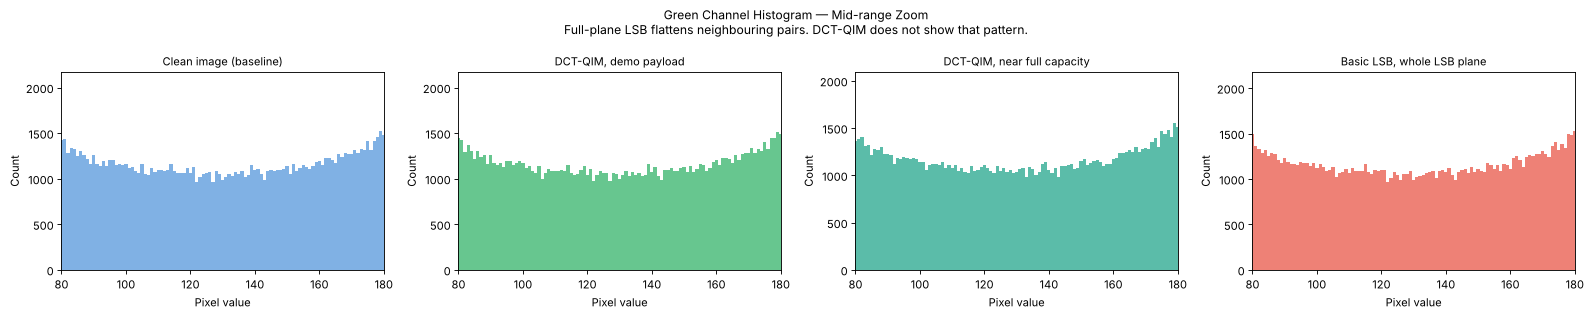

In [12]:
# The histogram plot that actually shows WHY chi-square catches LSB
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
labels = ['Clean image (baseline)', 'DCT-QIM, demo payload', 'DCT-QIM, near full capacity', 'Basic LSB, whole LSB plane']
imgs   = [orig, stego, dct_full, lsb_full]
clrs   = ['#4a90d9', '#27ae60', '#16a085', '#e74c3c']

for ax, img, label, color in zip(axes, imgs, labels, clrs):
    hist = np.bincount(img[:,:,1].flatten(), minlength=256)
    ax.bar(range(256), hist, color=color, alpha=0.7, width=1.0)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('Pixel value')
    ax.set_ylabel('Count')
    ax.set_xlim(80, 180)  # zoom into mid-range where changes show

plt.suptitle('Green Channel Histogram — Mid-range Zoom\nFull-plane LSB flattens neighbouring pairs. DCT-QIM does not show that pattern.', fontsize=11)
plt.tight_layout()
plt.show()

---
## Part 7 — Decode and Verify

In [13]:
print('Decoding...')
recovered = decode_image(STEGO_PATH, QUANTUM_KEY)

print(f'Original : {SECRET}')
print(f'Recovered: {recovered}')
print(f'\nExact match: {SECRET == recovered}')

# Wrong key
print('\n--- Wrong Key Test ---')
try:
    decode_image(STEGO_PATH, os.urandom(32))
except ValueError as e:
    print(f'Result with wrong key: {e}')
    print('Hard error — not garbled output. Correct behaviour.')

Decoding...
Original : [CONFIDENTIAL] Project codename: QSteg. This message was AES-256-GCM encrypted using a quantum-generated key before being embedded into DCT frequency coefficients. If you can read this, the system worked.
Recovered: [CONFIDENTIAL] Project codename: QSteg. This message was AES-256-GCM encrypted using a quantum-generated key before being embedded into DCT frequency coefficients. If you can read this, the system worked.

Exact match: True

--- Wrong Key Test ---
Result with wrong key: Payload length unreasonable — probably wrong key or corrupted image.
Hard error — not garbled output. Correct behaviour.


In [14]:
# Export key
key_package = {
    'key_hex'         : KEY_HEX,
    'key_b64'         : base64.b64encode(QUANTUM_KEY).decode(),
    'algorithm'       : 'AES-256-GCM + DCT-QIM steganography',
    'quantum_circuit' : '8-qubit Hadamard, 32 measurement rounds (AerSimulator)',
    'note'            : 'Demo key. Generate a fresh key for real use, send it over a separate secure channel, and never commit this file.'
}

with open('key_package.json', 'w') as f:
    json.dump(key_package, f, indent=2)

print('Key exported to key_package.json')
print(f'\nKey (hex): {KEY_HEX}')
print(f'Key (b64): {key_package["key_b64"]}')

Key exported to key_package.json

Key (hex): 850c6c46ad0c4e1221e0597aee9259908eafad3db01395b1c5018a29c7c54164
Key (b64): hQxsRq0MThIh4Fl67pJZkI6vrT2wE5WxxQGKKcfFQWQ=


---
## Results

In [15]:
print('=' * 60)
print('RESULTS')
print('=' * 60)
print()
print('Quantum Key')
print(f'  8-qubit Hadamard x 32 rounds = {len(QUANTUM_KEY)*8} bits (AerSimulator)')
print(f'  Bit balance: {100*KEY_BITS.count(1)/256:.1f}% ones / {100*KEY_BITS.count(0)/256:.1f}% zeros')
print()
print('Encryption')
print(f'  AES-256-GCM | payload: {meta["encrypted_bytes"]} bytes | auth: 128-bit tag')
print()
print('Steganography')
print(f'  Frequency domain DCT, 8x8 blocks, QIM delta={DELTA}')
print(f'  Block order: key-derived permutation')
print(f'  Demo payload: {meta["bits_used"]} / {meta["capacity_bits"]} bits ({meta["utilisation_pct"]}%), round-trip verified')
print()
print('Image Quality (demo payload)')
print(f'  PSNR : {psnr_val:.2f} dB')
print(f'  SSIM : {ssim_val:.6f}')
print()
print('Classic LSB steganalysis (flagged = looks embedded)')
print(f'  DCT-QIM demo payload : chi-sq p={chi_dct:.4f}, RS={rs_dct:.3f}  -> {"flagged" if results[cases[1][0]][2] else "not flagged"}')
print(f'  DCT-QIM near full    : chi-sq p={chi_full:.4f}, RS={rs_full:.3f}  -> {"flagged" if results[cases[2][0]][2] else "not flagged"}')
print(f'  Basic LSB whole plane: chi-sq p={chi_lsb:.4f}, RS={rs_lsb:.3f}  -> {"flagged" if results[cases[4][0]][2] else "not flagged"}')
print('  Caveat: these tests target LSB. No deep-learning detector was tested.')
print('=' * 60)


RESULTS

Quantum Key
  8-qubit Hadamard x 32 rounds = 256 bits (AerSimulator)
  Bit balance: 44.1% ones / 55.9% zeros

Encryption
  AES-256-GCM | payload: 236 bytes | auth: 128-bit tag

Steganography
  Frequency domain DCT, 8x8 blocks, QIM delta=20
  Block order: key-derived permutation
  Demo payload: 1920 / 16384 bits (11.72%), round-trip verified

Image Quality (demo payload)
  PSNR : 49.87 dB
  SSIM : 0.998170

Classic LSB steganalysis (flagged = looks embedded)
  DCT-QIM demo payload : chi-sq p=0.0000, RS=0.031  -> not flagged
  DCT-QIM near full    : chi-sq p=0.0000, RS=-0.092  -> not flagged
  Basic LSB whole plane: chi-sq p=0.1041, RS=0.931  -> flagged
  Caveat: these tests target LSB. No deep-learning detector was tested.


---
## Limitations — things I'm being upfront about

**AerSimulator is not real quantum hardware.**  
The simulator accurately models quantum mechanics, but the underlying randomness source is a classical PRNG inside the simulator. For actual quantum randomness you'd need IBM Quantum hardware via `qiskit-ibm-runtime`. The circuit and key generation code are identical — only the backend changes.

**JPEG will destroy the hidden data.**  
JPEG's lossy compression modifies DCT coefficients and breaks the embedded bits. Always save stego images as PNG.

**Key distribution is still a real problem.**  
The quantum key needs to reach the receiver securely. I export it manually in this project. In a real system you'd use QKD or asymmetric key exchange. This is not specific to this project — it's the fundamental problem in all symmetric-key systems.

**Modern deep-learning steganalysis is out of scope.**  
This system resists chi-square and RS analysis. It has not been tested against ML-based detectors like SRNet or Zhu-Net, which are trained specifically on frequency-domain steganography. Defeating those requires adaptive content-aware embedding — an active research problem.

**Capacity scales with image size.**  
A 256×256 image can hold roughly 500 characters. A 1024×1024 can hold ~8000.

**Decoding can fail on images with large saturated areas.**  
Clipping at 0 or 255 corrupts DCT coefficients. In my test on six standard photographs, five decoded correctly and one (the astronaut image, about 24% of green pixels near black or white) failed. The encoder now runs a round-trip check and raises an error instead of silently producing an undecodable image.

**The steganalysis here is limited.**  
Chi-square and RS analysis are designed for LSB embedding. Passing them says little about frequency-domain methods. At small payloads they also fail to flag basic LSB, so they are weak benchmarks.

**The cover image used here is synthetic.**  
The demo uses a generated gradient with noise. Results on real photographs will differ.